# Discovering the 3-Point Line with Competitive Learning

Can a competitive learning network find the NBA 3-point line using only where shots were taken? This notebook trains one on shot locations from 2000-01 to 2024-25 and tracks how its map of the court changes as the league moved toward the 3.

**Contents**

1. Data: counts, train and test split, heatmaps, shot distance, zone shares
2. Experiments 1 and 2: Finding the line in 2000-01 and 2024-25
3. Experiment 3: Sequential training across eras
4. Experiment 4: Polar inputs and the shape of the line
5. Limitations and possible improvements

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/BiyonWann/bballNeuro.git"

if "google.colab" in sys.modules:
    if not os.path.isdir("threept"):
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir("bballNeuro")
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
else:
    print("Not running in Colab, setup skipped")

Not running in Colab, setup skipped


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from threept import court, data

DATA_DIR = os.environ.get("BBALL_DATA_DIR", "data")
SEED = 0
N_TRAIN = 20000

## 1. Data

Shot-detail files come from the public GitHub repository `shufinskiy/nba_data`, which mirrors the NBA's official shot-chart data. Each row is one field-goal attempt. The model sees only `LOC_X` and `LOC_Y`. `SHOT_TYPE` and `SHOT_ZONE_BASIC` are used only for evaluation.

In [3]:
raw_shots = {}
cleaned_shots = {}
for season, start_year in data.SEASONS.items():
    raw_shots[season] = data.load_season(start_year, DATA_DIR)
    cleaned = data.clean_shots(raw_shots[season])
    cleaned_shots[season] = data.add_features(cleaned)

In [4]:
count_rows = []
for season, raw in raw_shots.items():
    missing = raw["LOC_X"].isna() | raw["LOC_Y"].isna()
    count_rows.append(
        {
            "season": season,
            "raw rows": len(raw),
            "games": raw["GAME_ID"].nunique(),
            "Backcourt rows": (raw["SHOT_ZONE_BASIC"] == "Backcourt").sum(),
            "missing coordinates": missing.sum(),
            "rows after cleaning": len(cleaned_shots[season]),
        }
    )
counts = pd.DataFrame(count_rows).set_index("season")
counts

,raw rows,games,Backcourt rows,missing coordinates,rows after cleaning
season,,,,,
2000-01,191662,1189,298,0,191364
2008-09,199030,1230,445,0,198585
2015-16,207893,1230,440,0,207453
2024-25,219527,1230,517,0,219010


### Train and test split

In [5]:
splits = {}
split_rows = []
for season, start_year in data.SEASONS.items():
    train, test = data.prepare_season(start_year, seed=SEED, n_train=N_TRAIN, data_dir=DATA_DIR)
    splits[season] = (train, test)
    shared_games = set(train["GAME_ID"]) & set(test["GAME_ID"])
    assert len(shared_games) == 0, f"{season}: games in both train and test"
    split_rows.append(
        {
            "season": season,
            "train rows": len(train),
            "test rows": len(test),
            "test games": test["GAME_ID"].nunique(),
            "shared games": len(shared_games),
        }
    )
pd.DataFrame(split_rows).set_index("season")

,train rows,test rows,test games,shared games
season,,,,
2000-01,20000,38292,238,0
2008-09,20000,39960,246,0
2015-16,20000,41735,246,0
2024-25,20000,44010,246,0


### Shot heatmaps

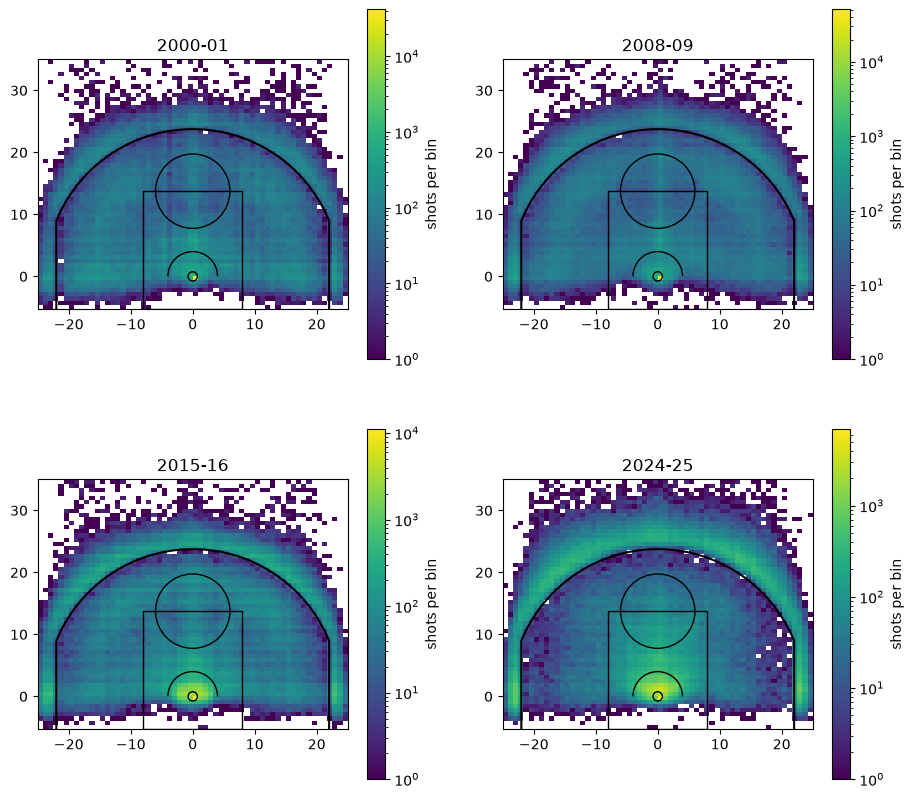

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (season, shots) in zip(axes.flat, cleaned_shots.items(), strict=True):
    court.plot_shot_heatmap(shots["x_ft"], shots["y_ft"], ax=ax)
    ax.set_title(season)
    fig.colorbar(ax.collections[0], ax=ax, label="shots per bin")
plt.show()

**Interpretation:** to be written

### Shot distance

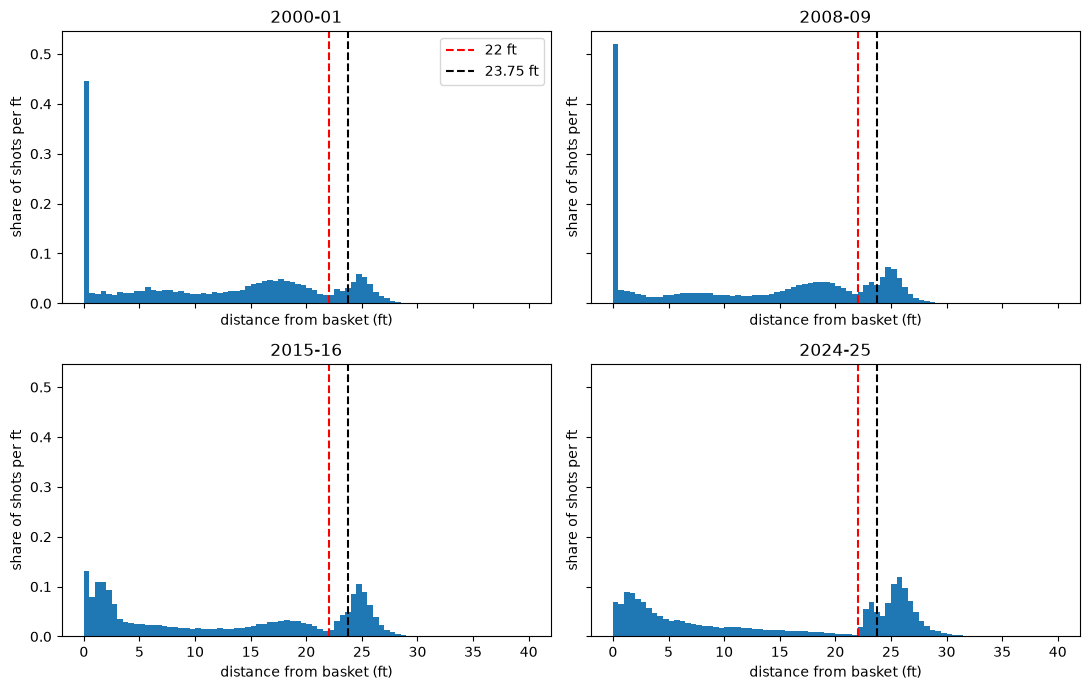

In [7]:
bins = np.arange(0, 40.5, 0.5)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (season, shots) in zip(axes.flat, cleaned_shots.items(), strict=True):
    ax.hist(shots["distance_ft"], bins=bins, density=True)
    ax.axvline(court.CORNER_THREE_X, color="red", linestyle="--", label="22 ft")
    ax.axvline(court.ARC_RADIUS, color="black", linestyle="--", label="23.75 ft")
    ax.set_title(season)
    ax.set_xlabel("distance from basket (ft)")
    ax.set_ylabel("share of shots per ft")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Interpretation:** to be written

### Shot share by zone

                       2000-01  2008-09  2015-16  2024-25
SHOT_ZONE_BASIC                                          
Restricted Area          0.294    0.328    0.325    0.279
In The Paint (Non-RA)    0.157    0.128    0.146    0.203
Mid-Range                0.380    0.322    0.246    0.098
Left Corner 3            0.021    0.034    0.038    0.056
Right Corner 3           0.021    0.030    0.035    0.052
Above the Break 3        0.126    0.158    0.209    0.312


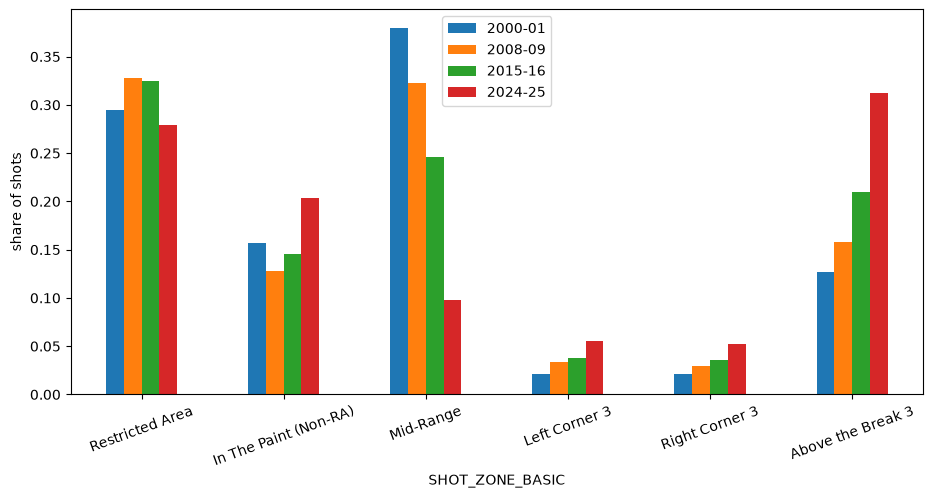

In [8]:
zone_share = pd.DataFrame()
for season, shots in cleaned_shots.items():
    zone_share[season] = shots["SHOT_ZONE_BASIC"].value_counts(normalize=True)
zone_share = zone_share.reindex(data.ZONES)
print(zone_share.round(3))
zone_share.plot.bar(figsize=(11, 5), ylabel="share of shots", rot=20)
plt.show()

**Interpretation:** to be written

## 2. Experiments 1 and 2: Finding the line in 2000-01 and 2024-25

Both seasons use court coordinates in feet (cartesian inputs). Each network trains on the same 20,000 shots as section 1 and is scored on every shot from the held-out games. Every run uses 5 seeds, and seed 0 is the representative seed for the per-cell tables and single-seed plots.

The k-means and random rows are the baselines. The majority row is the accuracy of always guessing the more common shot type in the training set.

In [9]:
from threept import experiments, metrics, network

SEEDS = (0, 1, 2, 3, 4)
SEASONS_12 = ["2000-01", "2024-25"]
N_CELLS = 6
SUMMARY_COLUMNS = ["accuracy", "qe", "ari", "dead_cells", "mean_arc_purity"]

In [10]:
season_results = {}
season_weights = {}
baseline_results = {}
for season in SEASONS_12:
    train, test = splits[season]
    key = (season, N_CELLS)
    season_results[key], season_weights[key] = experiments.run_season(
        train, test, kind="cartesian", n_cells=N_CELLS, seeds=SEEDS
    )
    baseline_results[key] = experiments.run_baselines(
        train, test, kind="cartesian", n_cells=N_CELLS, seeds=SEEDS
    )
    assert len(season_results[key]) == len(SEEDS)
    assert len(baseline_results[key]) == 2 * len(SEEDS)
    print(season, "K =", N_CELLS)
    print(season_results[key].round(3).to_string(index=False))
    print()

2000-01 K = 6
 seed  accuracy  baseline    qe   ari   rim  mid_range  beyond_20  mean_arc_purity  dead_cells  kmeans_gap
    0      0.83      0.83 4.315 0.389 0.430      0.266      0.304            0.406           0       0.355
    1      0.83      0.83 4.310 0.387 0.427      0.262      0.310            0.399           0       0.305
    2      0.83      0.83 4.329 0.383 0.431      0.260      0.309            0.399           0       0.233
    3      0.83      0.83 4.332 0.388 0.430      0.264      0.306            0.402           0       0.310
    4      0.83      0.83 4.288 0.386 0.429      0.260      0.311            0.396           0       0.309



2024-25 K = 6
 seed  accuracy  baseline    qe   ari   rim  mid_range  beyond_20  mean_arc_purity  dead_cells  kmeans_gap
    0     0.943     0.583 4.425 0.522 0.402      0.124      0.474            0.868           0       4.179
    1     0.944     0.583 4.440 0.518 0.405      0.122      0.473            0.870           0       4.196
    2     0.944     0.583 4.457 0.514 0.411      0.116      0.472            0.870           0       4.057
    3     0.944     0.583 4.474 0.511 0.410      0.118      0.472            0.871           0       4.368
    4     0.944     0.583 4.447 0.519 0.405      0.122      0.473            0.869           0       4.196



In [11]:
summary_tables = {}
for season in SEASONS_12:
    key = (season, N_CELLS)
    baselines = baseline_results[key]
    network_summary = experiments.summarize(season_results[key])
    kmeans_summary = experiments.summarize(baselines[baselines["method"] == "kmeans"])
    random_summary = experiments.summarize(baselines[baselines["method"] == "random"])
    summary_tables[season] = pd.concat(
        {
            "network": network_summary.loc[SUMMARY_COLUMNS],
            "kmeans": kmeans_summary.loc[SUMMARY_COLUMNS],
            "random": random_summary.loc[SUMMARY_COLUMNS],
            "majority": network_summary.loc[["baseline"]],
        }
    )
    gap = network_summary.loc["kmeans_gap"]
    print(f"{season} K = {N_CELLS}: mean k-means gap {gap['mean']:.2f} ft (std {gap['std']:.2f})")
summary_table = pd.concat(summary_tables, axis=1)
summary_table.round(3)

2000-01 K = 6: mean k-means gap 0.30 ft (std 0.04)
2024-25 K = 6: mean k-means gap 4.20 ft (std 0.11)


2000-01        2024-25       
                            mean    std    mean    std
network  accuracy          0.830  0.000   0.944  0.001
         qe                4.315  0.018   4.449  0.018
         ari               0.387  0.002   0.517  0.004
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.400  0.004   0.870  0.001
kmeans   accuracy          0.830  0.000   0.917  0.000
         qe                4.305  0.000   4.464  0.000
         ari               0.387  0.000   0.441  0.000
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.399  0.000   0.830  0.000
random   accuracy          0.847  0.017   0.894  0.025
         qe                6.253  0.823   6.711  0.662
         ari               0.338  0.060   0.424  0.040
         dead_cells        0.800  0.447   0.000  0.000
         mean_arc_purity   0.520  0.147   0.906  0.027
majority baseline          0.830  0.000   0.583  0.000

In [12]:
allocation_tables = {}
for season in SEASONS_12:
    per_seed = []
    for weights in season_weights[(season, N_CELLS)]:
        distances = metrics.prototype_distances(weights, "cartesian")
        per_seed.append(metrics.cell_allocation(distances))
    per_seed = pd.DataFrame(per_seed)
    assert (per_seed.sum(axis=1) == N_CELLS).all()
    allocation_tables[season] = pd.DataFrame({"mean": per_seed.mean(), "seed 0": per_seed.iloc[0]})
allocation_table = pd.concat(allocation_tables, axis=1)
allocation_table.round(2)

2000-01        2024-25       
             mean seed 0    mean seed 0
rim           1.0      1     1.0      1
mid_range     2.0      2     1.0      1
beyond_20     3.0      3     4.0      4

**Interpretation:** to be written

### K sweep

In [13]:
for n_cells in (12, 20):
    for season in SEASONS_12:
        train, test = splits[season]
        key = (season, n_cells)
        season_results[key], season_weights[key] = experiments.run_season(
            train, test, kind="cartesian", n_cells=n_cells, seeds=SEEDS
        )
        baseline_results[key] = experiments.run_baselines(
            train, test, kind="cartesian", n_cells=n_cells, seeds=SEEDS
        )
        assert len(season_results[key]) == len(SEEDS)
        assert len(baseline_results[key]) == 2 * len(SEEDS)

In [14]:
for n_cells in (12, 20):
    sweep_tables = {}
    for season in SEASONS_12:
        baselines = baseline_results[(season, n_cells)]
        network_summary = experiments.summarize(season_results[(season, n_cells)])
        kmeans_summary = experiments.summarize(baselines[baselines["method"] == "kmeans"])
        random_summary = experiments.summarize(baselines[baselines["method"] == "random"])
        sweep_tables[season] = pd.concat(
            {
                "network": network_summary.loc[SUMMARY_COLUMNS],
                "kmeans": kmeans_summary.loc[SUMMARY_COLUMNS],
                "random": random_summary.loc[SUMMARY_COLUMNS],
                "majority": network_summary.loc[["baseline"]],
            }
        )
    sweep_table = pd.concat(sweep_tables, axis=1)
    print(f"Summary at K = {n_cells}")
    print(sweep_table.round(3).to_string())
    print()

Summary at K = 12
                         2000-01        2024-25       
                            mean    std    mean    std
network  accuracy          0.853  0.008   0.980  0.003
         qe                3.007  0.046   3.049  0.083
         ari               0.459  0.004   0.554  0.056
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.511  0.029   0.952  0.005
kmeans   accuracy          0.860  0.003   0.971  0.001
         qe                2.966  0.003   2.870  0.009
         ari               0.455  0.003   0.528  0.021
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.507  0.015   0.934  0.002
random   accuracy          0.869  0.026   0.931  0.032
         qe                4.715  0.519   5.021  1.011
         ari               0.389  0.043   0.361  0.095
         dead_cells        2.200  1.924   0.000  0.000
         mean_arc_purity   0.620  0.086   0.937  0.015
majority baseline          0.830  0.000   0.583

In [15]:
for n_cells in (12, 20):
    sweep_allocation = {}
    for season in SEASONS_12:
        per_seed = []
        for weights in season_weights[(season, n_cells)]:
            distances = metrics.prototype_distances(weights, "cartesian")
            per_seed.append(metrics.cell_allocation(distances))
        per_seed = pd.DataFrame(per_seed)
        assert (per_seed.sum(axis=1) == n_cells).all()
        sweep_allocation[season] = pd.DataFrame(
            {"mean": per_seed.mean(), "seed 0": per_seed.iloc[0]}
        )
    print(f"Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = {n_cells}")
    print(pd.concat(sweep_allocation, axis=1).round(2).to_string())
    print()

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 12
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           2.4      3     3.0      2
mid_range     4.6      3     3.6      4
beyond_20     5.0      6     5.4      6

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 20
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           3.8      4     4.6      5
mid_range     8.8      8     6.0      7
beyond_20     7.4      8     9.4      8



### Seed 0, K = 6

In [16]:
test_labels_k6 = {}
for season in SEASONS_12:
    train, test = splits[season]
    weights = season_weights[(season, N_CELLS)][0]
    train_inputs = data.get_inputs(train, "cartesian")
    test_inputs = data.get_inputs(test, "cartesian")
    train_labels = network.assign(train_inputs, weights)
    test_labels_k6[season] = network.assign(test_inputs, weights)
    cell_table = pd.DataFrame(
        {
            "distance (ft)": metrics.prototype_distances(weights, "cartesian"),
            "angle (deg)": np.degrees(metrics.prototype_angles(weights, "cartesian")),
            "3PT share (test)": metrics.three_point_purity(
                test_labels_k6[season], test["is_three"].to_numpy(), N_CELLS
            ),
            "wins (train)": network.count_wins(train_inputs, weights),
        }
    )
    cell_table.index.name = "cell"
    assert cell_table["wins (train)"].sum() == len(train)
    dead_cells = season_results[(season, N_CELLS)].loc[0, "dead_cells"]
    assert (cell_table["wins (train)"] == 0).sum() == dead_cells
    print(f"{season}, seed 0, K = {N_CELLS}")
    print(cell_table.round(3).to_string())
    print()

2000-01, seed 0, K = 6
      distance (ft)  angle (deg)  3PT share (test)  wins (train)
cell                                                            
0            21.297      -40.691             0.435          2155
1            21.601       39.830             0.429          2252
2             1.671        0.449             0.000          8604
3            16.234       81.000             0.179          2468
4            21.021       -0.715             0.353          1643
5            16.066      -80.589             0.160          2878

2024-25, seed 0, K = 6
      distance (ft)  angle (deg)  3PT share (test)  wins (train)
cell                                                            
0             1.815        4.315             0.000          7888
1            21.937      -80.688             0.822          1654
2            10.229       -0.120             0.000          2491
3            21.628       74.099             0.819          1815
4            25.105      -30.541           

In [17]:
for season in SEASONS_12:
    train, test = splits[season]
    confusion = metrics.zone_confusion(
        test_labels_k6[season], test["SHOT_ZONE_BASIC"].to_numpy(), data.ZONES, N_CELLS
    )
    assert confusion.to_numpy().sum() == len(test)
    print(f"{season}, seed 0, K = {N_CELLS}: test shots by cell (rows) and official zone (columns)")
    print(confusion.to_string())
    print()

2000-01, seed 0, K = 6: test shots by cell (rows) and official zone (columns)
zone  Restricted Area  In The Paint (Non-RA)  Mid-Range  Left Corner 3  Right Corner 3  Above the Break 3
cell                                                                                                     
0                   0                    178       2205              0               0               1831
1                   0                    216       2275              0               0               1867
2               11166                   5310          8              0               0                  0
3                   0                     11       3817              0             788                 48
4                   0                    310       1673              0               0               1075
5                   0                     39       4594            855               0                 26

2024-25, seed 0, K = 6: test shots by cell (rows) and official zone (colu

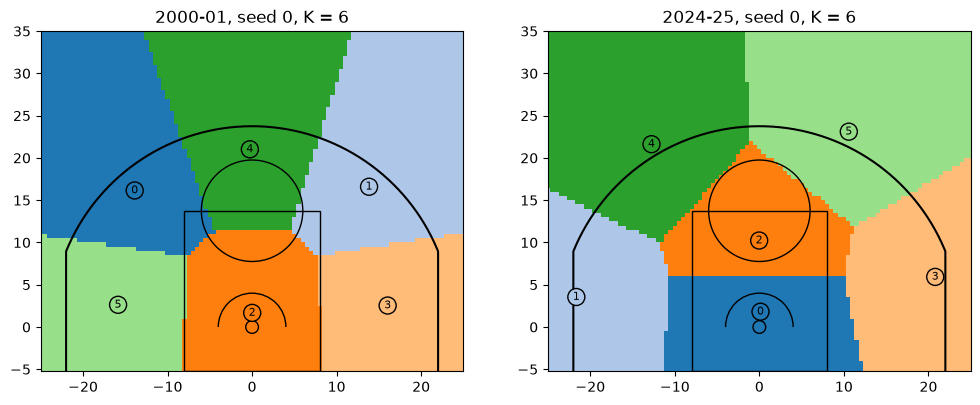

In [18]:
grid_x, grid_y = court.court_grid()
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
grid_inputs = data.court_to_inputs(grid_points, "cartesian")
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, season in zip(axes, SEASONS_12, strict=True):
    weights = season_weights[(season, N_CELLS)][0]
    grid_labels = network.assign(grid_inputs, weights).reshape(grid_x.shape)
    court.plot_zone_map(grid_x, grid_y, grid_labels, ax=ax)
    court.plot_prototypes(weights, ax=ax)
    ax.set_title(f"{season}, seed 0, K = {N_CELLS}")
plt.show()

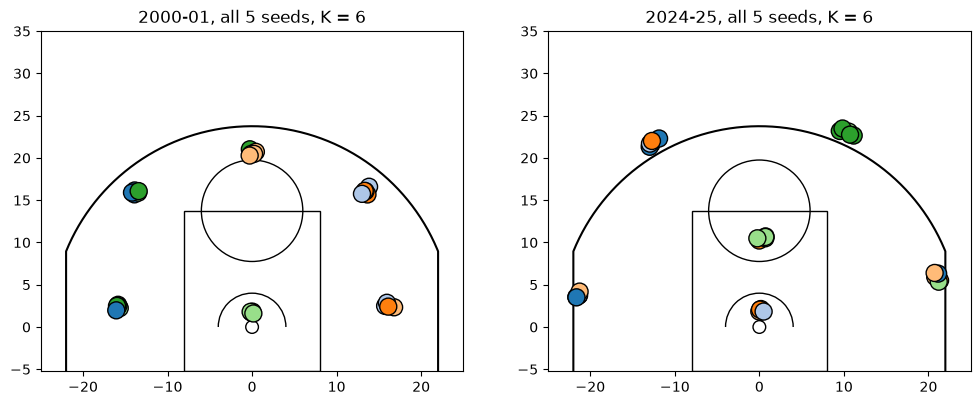

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, season in zip(axes, SEASONS_12, strict=True):
    court.draw_half_court(ax=ax)
    for weights in season_weights[(season, N_CELLS)]:
        court.plot_prototypes(weights, ax=ax, numbered=False)
    ax.set_title(f"{season}, all {len(SEEDS)} seeds, K = {N_CELLS}")
plt.show()

**Interpretation:** to be written

## 3. Experiment 3: Sequential training across eras

One network trains through the four seasons in time order, with the weights carried from each season to the next and the learning rate reset every season. It uses court coordinates, K = 6 and the same 5 seeds as section 2. Seed 0 is the representative seed for single-seed tables and plots.

In [20]:
seasons = []
for name in data.SEASONS:
    train, test = splits[name]
    seasons.append((name, train, test))

sequential_weights = {}
sequential_tables = []
for seed in SEEDS:
    sequential_weights[seed], table = experiments.run_sequential(
        seasons, kind="cartesian", n_cells=N_CELLS, seed=seed
    )
    table["seed"] = seed
    sequential_tables.append(table)
    assert len(sequential_weights[seed]) == len(seasons)
    for weights in sequential_weights[seed]:
        assert weights.shape == (N_CELLS, 2)
    first_season_weights = season_weights[("2000-01", N_CELLS)][seed]
    assert np.array_equal(sequential_weights[seed][0], first_season_weights)
sequential_results = pd.concat(sequential_tables, ignore_index=True)

first_rows = sequential_results["season"] == "2000-01"
shares = sequential_results[["rim", "mid_range", "beyond_20"]].sum(axis=1)
assert len(sequential_results) == len(SEEDS) * len(seasons)
assert sequential_results.loc[first_rows, "mean_movement"].isna().all()
assert sequential_results.loc[~first_rows, "mean_movement"].notna().all()
assert np.allclose(shares, 1)

### Per-season table

In [21]:
majority_by_season = {}
for name, train, test in seasons:
    majority_by_season[name] = metrics.majority_baseline_accuracy(
        train["is_three"], test["is_three"]
    )
sequential_results["majority"] = sequential_results["season"].map(majority_by_season)

table_columns = ["mean_movement", "rim", "mid_range", "beyond_20", "accuracy", "majority"]
seed_zero = sequential_results[sequential_results["seed"] == 0]
print("Seed 0")
seed_zero_table = seed_zero.set_index("season")[table_columns]
print(seed_zero_table.round(3).to_string())
print()
print(f"Mean across {len(SEEDS)} seeds")
mean_table = sequential_results.groupby("season", sort=False)[table_columns].mean()
print(mean_table.round(3).to_string())

Seed 0
         mean_movement    rim  mid_range  beyond_20  accuracy  majority
season                                                                 
2000-01            NaN  0.430      0.266      0.304     0.830     0.830
2008-09          0.996  0.446      0.219      0.335     0.773     0.773
2015-16          0.814  0.466      0.186      0.349     0.769     0.714
2024-25          2.593  0.499      0.000      0.501     0.916     0.583

Mean across 5 seeds
         mean_movement    rim  mid_range  beyond_20  accuracy  majority
season                                                                 
2000-01            NaN  0.430      0.263      0.308     0.830     0.830
2008-09          1.158  0.446      0.219      0.335     0.773     0.773
2015-16          0.837  0.466      0.182      0.352     0.766     0.714
2024-25          2.695  0.500      0.000      0.500     0.917     0.583


### Cell allocation by season

In [22]:
allocation_rows = []
for seed in SEEDS:
    for name, weights in zip(data.SEASONS, sequential_weights[seed], strict=True):
        distances = metrics.prototype_distances(weights, "cartesian")
        row = metrics.cell_allocation(distances)
        assert row["rim"] + row["mid_range"] + row["beyond_20"] == N_CELLS
        row["season"] = name
        row["seed"] = seed
        allocation_rows.append(row)
allocation = pd.DataFrame(allocation_rows)

allocation_columns = ["rim", "mid_range", "beyond_20"]
seed_zero_allocation = allocation[allocation["seed"] == 0].set_index("season")
mean_allocation = allocation.groupby("season", sort=False)[allocation_columns].mean()
print("Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft")
pd.concat(
    {"mean": mean_allocation, "seed 0": seed_zero_allocation[allocation_columns]}, axis=1
).round(2)

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft


mean                     seed 0                    
         rim mid_range beyond_20    rim mid_range beyond_20
season                                                     
2000-01  1.0       2.0       3.0      1         2         3
2008-09  1.0       2.0       3.0      1         2         3
2015-16  1.0       2.0       3.0      1         2         3
2024-25  1.0       0.0       5.0      1         0         5

### Prototype paths, seed 0

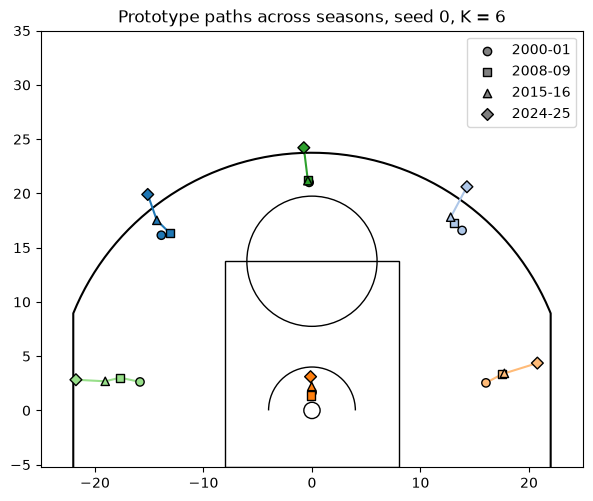

In [23]:
fig, ax = plt.subplots(figsize=(7, 8))
court.draw_half_court(ax=ax)
court.plot_prototype_paths(sequential_weights[0], list(data.SEASONS), ax=ax)
ax.set_title(f"Prototype paths across seasons, seed 0, K = {N_CELLS}")
plt.show()

### Arc and mid-range shares by season

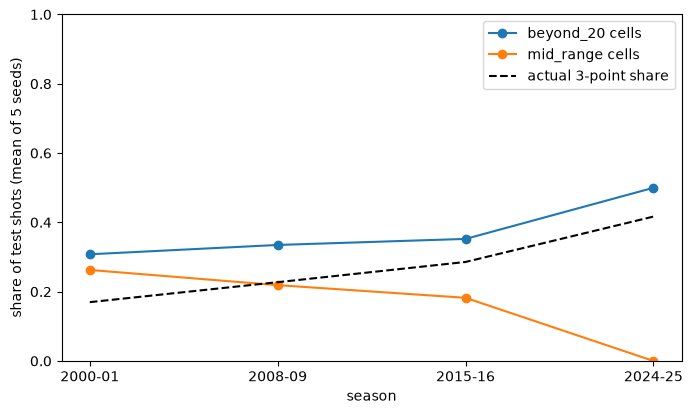

In [24]:
three_point_share = []
for name in data.SEASONS:
    three_point_share.append(splits[name][1]["is_three"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mean_table.index, mean_table["beyond_20"], marker="o", label="beyond_20 cells")
ax.plot(mean_table.index, mean_table["mid_range"], marker="o", label="mid_range cells")
ax.plot(
    mean_table.index,
    three_point_share,
    linestyle="--",
    color="black",
    label="actual 3-point share",
)
ax.set_xlabel("season")
ax.set_ylabel(f"share of test shots (mean of {len(SEEDS)} seeds)")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

### Final sequential map against a fresh 2024-25 network

In [25]:
gap_rows = []
for seed in SEEDS:
    final_weights = sequential_weights[seed][-1]
    fresh_weights = season_weights[("2024-25", N_CELLS)][seed]
    gap = metrics.prototype_gap(final_weights, fresh_weights)
    assert gap >= 0
    gap_rows.append({"seed": seed, "gap (ft)": gap})
gap_table = pd.DataFrame(gap_rows).set_index("seed")
print(gap_table.round(2).to_string())
print(f"mean gap {gap_table['gap (ft)'].mean():.2f} ft")

      gap (ft)
seed          
0         4.17
1         4.33
2         4.09
3         4.44
4         3.98
mean gap 4.20 ft


**Interpretation:** to be written

## 4. Experiment 4: Polar inputs and the shape of the line

## 5. Limitations and possible improvements